<a href="https://colab.research.google.com/github/a2w3r4/PINNs/blob/main/Neural_Ordinary_Differential_Eq'n.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install torchdiffeq

In [3]:
import torch
import torch.nn as nn
import torch.optim as optim

import numpy as np
from tqdm.notebook import tqdm
import time

import matplotlib.pyplot as plt
%matplotlib inline

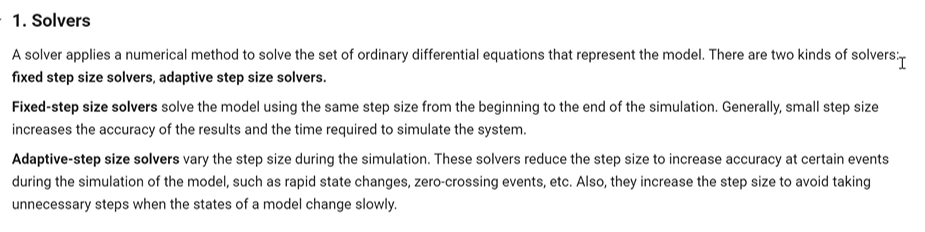

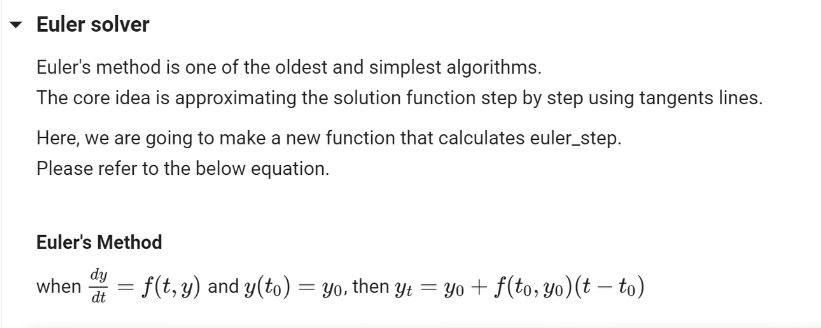

In [4]:
def euler(func, t, dt, y):
    return y + dt * func(t, y)

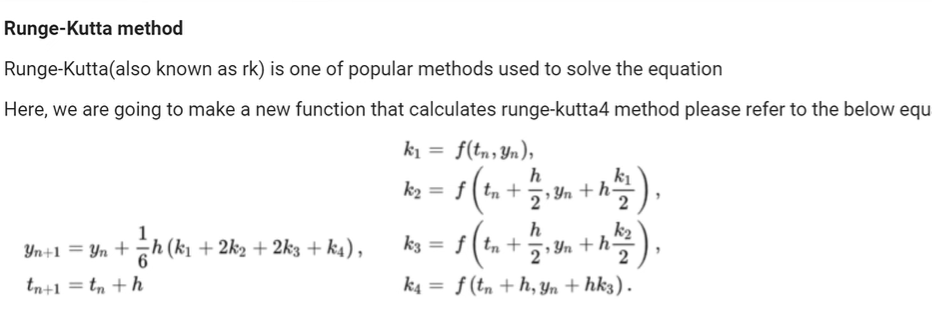

In [5]:
def rk4(func, t, dt, y):
  _one_sixth = 1/6
  half_dt = dt * 0.5

  k1 = func(t, y)
  k2 = func(t + half_dt, y + half_dt * k1)
  k3 = func(t + half_dt, y + half_dt * k2)
  k4 = func(t + dt, y + dt * k3)

  return y + dt * (_one_sixth * k1 + _one_sixth * k2 + _one_sixth * k3 + _one_sixth * k4)

#2. Neural ODEs (Ordinary Differential Eq'n)

In this, we're going to implement Neural ODEs

In [6]:
class NeuralODE(nn.Module):
  def __init__(self, func):
    super().__init__()
    self.func = func

  def forward(self, y0, t, solver):      # self - function, y0 - initial value, t = time-stamp that we want in our values, solver = kind of solver we want to use in neural network model (either euler or rk4 solver)
    solution = torch.empty(len(t), *y0.shape, dtype=y0.dtype, device=y0.device)
    solution[0] = y0

    j = 1
    for t0, t1 in zip(t[:-1], t[1:]):
      y1 = solver(self.func, t0, t1 - t0, y0)
      solution[j] = y1
      j += 1
      y0 = y1

    return solution

# 3. Experiments

we are going to check out NODEs result by giving dynamic of cos(t). The result will be sin(t)

In [7]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

y0 = torch.Tensor([[0]]).to(device)
t = torch.linspace(0, 6 * np.pi, 1500).to(device)

class cos(nn.Module):
  def forward(self, t, y):
    return torch.cos(t)

In [8]:
ode_test = NeuralODE(cos()).to(device)
test_result = ode_test(y0=y0, t=t, solver=euler)

# make sure you transpose
test_result = test_result.transpose(0, 1)

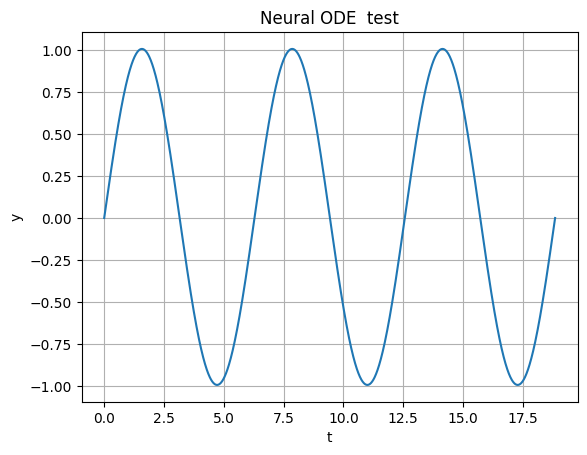

In [9]:
# visualize result
fig = plt.figure()
ax = fig.add_subplot(1, 1, 1)
ax.set_title('Neural ODE  test')
ax.set_xlabel('t')
ax.set_ylabel('y')
ax.plot(t.cpu().numpy(), test_result[0].detach().cpu().numpy())
plt.grid(True)
plt.show()


3-2. **sprial dataset**

Here, we are going to test our Neural ODEs in toy sprial dataset.

In [10]:
data_size = 2000

In [11]:
# generate toy dataset
true_y0 = torch.tensor([[2.0, 0.0]]).to(device)
t = torch.linspace(0., 25., data_size).to(device)
true_A = torch.tensor([[-0.1, 2.0], [-2.0, -0.1]]).to(device)

class Lambda(nn.Module):
  def forward(self, t, y):
    return torch.mm(y**3, true_A)

with torch.no_grad():
  node = NeuralODE(func=Lambda()).to(device)
  true_y = node(y0=true_y0, t=t, solver=rk4)

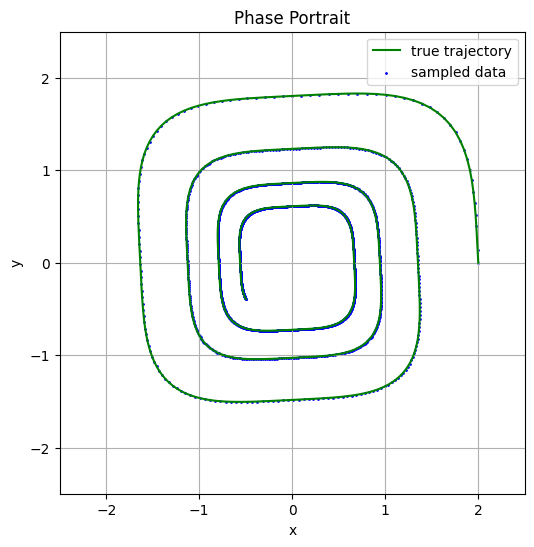

In [12]:
def visualize(true_y, pred_y=None):
    fig = plt.figure(figsize=(6, 6), facecolor='white')
    ax = fig.add_subplot(111)
    ax.set_title('Phase Portrait')
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.plot(true_y.cpu().numpy()[:, 0, 0], true_y.cpu().numpy()[:, 0, 1], 'green', label='true trajectory')
    ax.scatter(true_y.cpu().numpy()[:, 0, 0], true_y.cpu().numpy()[:, 0, 1], color='blue', label='sampled data', s=1)
    if pred_y is not None:
        ax.plot(pred_y.cpu().numpy()[:, 0, 0], pred_y.cpu().numpy()[:, 0, 1], 'red', label='learned trajectory')
    ax.set_xlim(-2.5, 2.5)
    ax.set_ylim(-2.5, 2.5)
    plt.legend()
    plt.grid(True)
    plt.show()

visualize(true_y)

In [13]:
batch_time = 10
batchh_size = 16
def get_batch():
  s = torch.from_numpy(np.random.choice(np.arange(data_size - batch_time, dtype=np.int64), batchh_size, replace=False))
  batch_y0 = true_y[s]
  batch_t = t[:batch_time]
  batch_y = torch.stack([true_y[s + i] for i in range(batch_time)], dim=0)
  return batch_y0.to(device), batch_t.to(device), batch_y.to(device)

In [14]:
# define dynamic function
class ODEFunc(nn.Module):
  def __init__(self):
    super().__init__()
    ### TO-DO: Make our own ODE Network!
    self.net = nn.Sequential(nn.Linear(2,50),
                            nn.Tanh(),
                            nn.Linear(50, 2))

    for m in self.net.modules():
      if isinstance(m, nn.Linear):
        nn.init.kaiming_normal_(m.weight)
        nn.init.constant_(m.bias, 0)

  def forward(self, t, y):
    output = self.net(y**3)
    return output

  0%|          | 0/401 [00:00<?, ?it/s]

Iter 0000 | Total Loss 6.323477


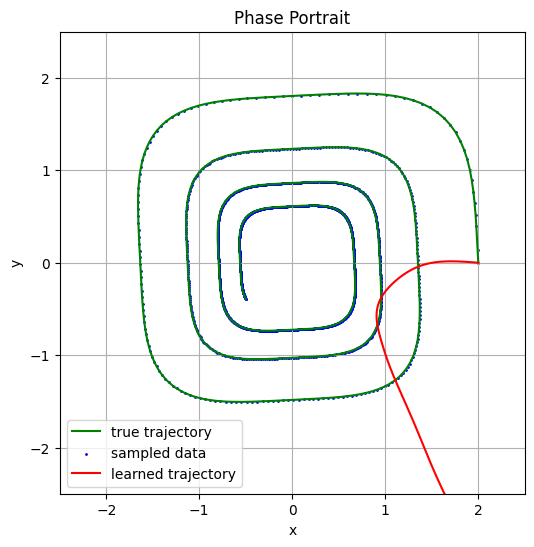

process time: 1.8015849590301514 sec
process time: 1.8320066928863525 sec
process time: 1.8563215732574463 sec
process time: 1.881394863128662 sec
process time: 1.9048194885253906 sec
process time: 1.9347822666168213 sec
process time: 1.9620647430419922 sec
process time: 1.9871151447296143 sec
process time: 2.012066125869751 sec
process time: 2.0406851768493652 sec
process time: 2.068760633468628 sec
process time: 2.0917160511016846 sec
process time: 2.1133151054382324 sec
process time: 2.140148401260376 sec
process time: 2.161853075027466 sec
process time: 2.1839218139648438 sec
process time: 2.2068824768066406 sec
process time: 2.235234022140503 sec
process time: 2.264054775238037 sec
process time: 2.2881815433502197 sec
process time: 2.3105721473693848 sec
process time: 2.332916736602783 sec
process time: 2.3575069904327393 sec
process time: 2.388657331466675 sec
process time: 2.4112653732299805 sec
process time: 2.451920509338379 sec
process time: 2.4756641387939453 sec
process tim

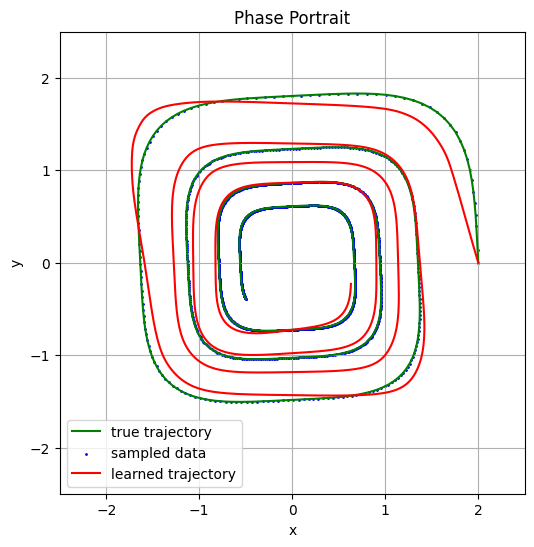

process time: 4.612679719924927 sec
process time: 4.648038387298584 sec
process time: 4.6718761920928955 sec
process time: 4.701510190963745 sec
process time: 4.724092245101929 sec
process time: 4.745976686477661 sec
process time: 4.767568349838257 sec
process time: 4.789320230484009 sec
process time: 4.817301988601685 sec
process time: 4.844469308853149 sec
process time: 4.869685411453247 sec
process time: 4.89336633682251 sec
process time: 4.928534030914307 sec
process time: 4.954195976257324 sec
process time: 4.978649139404297 sec
process time: 5.002446174621582 sec
process time: 5.032240390777588 sec
process time: 5.0615339279174805 sec
process time: 5.0875043869018555 sec
process time: 5.110423803329468 sec
process time: 5.139703273773193 sec
process time: 5.162342309951782 sec
process time: 5.1845924854278564 sec
process time: 5.2078163623809814 sec
process time: 5.2309651374816895 sec
process time: 5.281844615936279 sec
process time: 5.308929443359375 sec
process time: 5.3331491

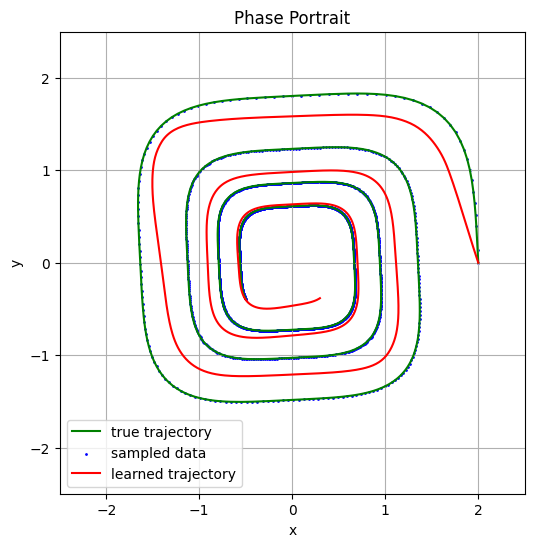

process time: 7.47214937210083 sec
process time: 7.507230758666992 sec
process time: 7.535773277282715 sec
process time: 7.569116830825806 sec
process time: 7.607617616653442 sec
process time: 7.640004634857178 sec
process time: 7.670856237411499 sec
process time: 7.6984312534332275 sec
process time: 7.725008487701416 sec
process time: 7.754410266876221 sec
process time: 7.787612676620483 sec
process time: 7.812782049179077 sec
process time: 7.8379411697387695 sec
process time: 7.8628222942352295 sec
process time: 7.898103713989258 sec
process time: 7.92878270149231 sec
process time: 7.959200382232666 sec
process time: 7.989288568496704 sec
process time: 8.02739405632019 sec
process time: 8.053146123886108 sec
process time: 8.080127477645874 sec
process time: 8.103987455368042 sec
process time: 8.139243602752686 sec
process time: 8.167248725891113 sec
process time: 8.190411567687988 sec
process time: 8.214422941207886 sec
process time: 8.245342254638672 sec
process time: 8.270806074142

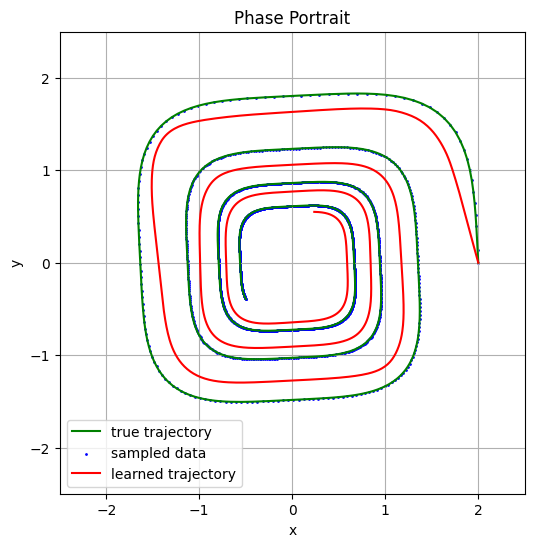

process time: 10.480776309967041 sec
process time: 10.509150981903076 sec
process time: 10.537081480026245 sec
process time: 10.560866594314575 sec
process time: 10.594071388244629 sec
process time: 10.617668628692627 sec
process time: 10.641026735305786 sec
process time: 10.664547204971313 sec
process time: 10.712467670440674 sec
process time: 10.751918315887451 sec
process time: 10.777496099472046 sec
process time: 10.812165975570679 sec
process time: 10.838246583938599 sec
process time: 10.864378452301025 sec
process time: 10.890164613723755 sec
process time: 10.932256698608398 sec
process time: 10.968395233154297 sec
process time: 10.993370771408081 sec
process time: 11.019505739212036 sec
process time: 11.054405927658081 sec
process time: 11.079349040985107 sec
process time: 11.101647853851318 sec
process time: 11.12475299835205 sec
process time: 11.159862041473389 sec
process time: 11.1900954246521 sec
process time: 11.217471599578857 sec
process time: 11.243471622467041 sec
proc

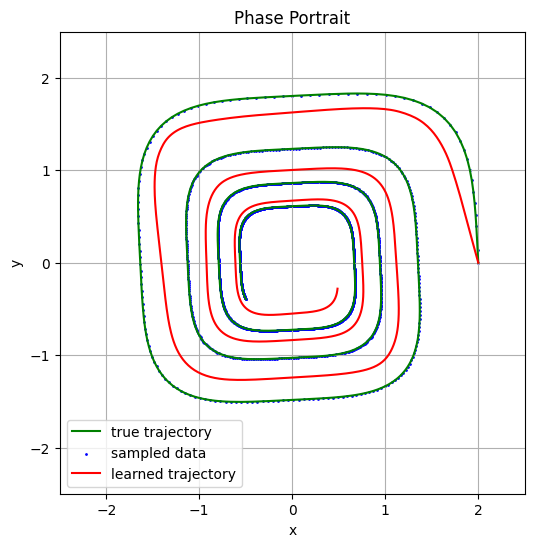

process time: 13.476666450500488 sec
process time: 13.526694774627686 sec
process time: 13.55223298072815 sec
process time: 13.577921390533447 sec
process time: 13.617956399917603 sec
process time: 13.644889116287231 sec
process time: 13.669886112213135 sec
process time: 13.700845956802368 sec
process time: 13.746122121810913 sec
process time: 13.771663904190063 sec
process time: 13.797155141830444 sec
process time: 13.839517831802368 sec
process time: 13.877052068710327 sec
process time: 13.905332565307617 sec
process time: 13.93460988998413 sec
process time: 13.972549438476562 sec
process time: 14.030097961425781 sec
process time: 14.05567741394043 sec
process time: 14.083139181137085 sec
process time: 14.125910520553589 sec
process time: 14.151798009872437 sec
process time: 14.177664756774902 sec
process time: 14.207256555557251 sec
process time: 14.24672245979309 sec
process time: 14.274853467941284 sec
process time: 14.30002737045288 sec
process time: 14.325680017471313 sec
proces

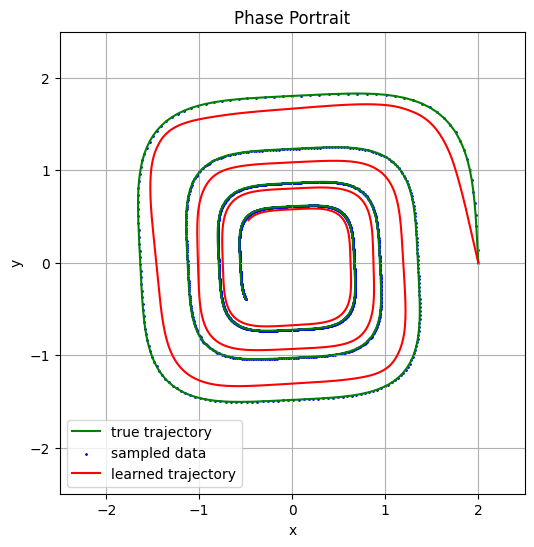

process time: 16.64780855178833 sec
process time: 16.6815025806427 sec
process time: 16.709661722183228 sec
process time: 16.73695397377014 sec
process time: 16.775020599365234 sec
process time: 16.80031108856201 sec
process time: 16.825859546661377 sec
process time: 16.852217435836792 sec
process time: 16.895334243774414 sec
process time: 16.94214940071106 sec
process time: 16.974788188934326 sec
process time: 17.014038801193237 sec
process time: 17.038925409317017 sec
process time: 17.069169998168945 sec
process time: 17.096656799316406 sec
process time: 17.132319450378418 sec
process time: 17.161306858062744 sec
process time: 17.186679363250732 sec
process time: 17.212010860443115 sec
process time: 17.249261617660522 sec
process time: 17.273364067077637 sec
process time: 17.298646450042725 sec
process time: 17.321231603622437 sec
process time: 17.356455087661743 sec
process time: 17.38381290435791 sec
process time: 17.40710949897766 sec
process time: 17.431652784347534 sec
process t

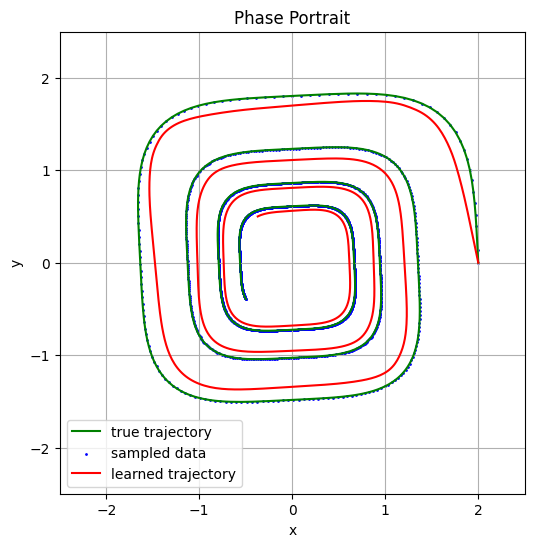

process time: 19.640912532806396 sec
process time: 19.70206046104431 sec
process time: 19.77107882499695 sec
process time: 19.81392216682434 sec
process time: 19.856712341308594 sec
process time: 19.886178016662598 sec
process time: 19.916797161102295 sec
process time: 19.96131992340088 sec
process time: 19.98742175102234 sec
process time: 20.013118743896484 sec
process time: 20.054681301116943 sec
process time: 20.09854793548584 sec
process time: 20.127016067504883 sec
process time: 20.1530978679657 sec
process time: 20.177964687347412 sec
process time: 20.21819543838501 sec
process time: 20.2431321144104 sec
process time: 20.26899766921997 sec
process time: 20.29309344291687 sec
process time: 20.337379693984985 sec
process time: 20.3632550239563 sec
process time: 20.39165735244751 sec
process time: 20.416353702545166 sec
process time: 20.45965027809143 sec
process time: 20.484541416168213 sec
process time: 20.51323938369751 sec
process time: 20.541620016098022 sec
process time: 20.58

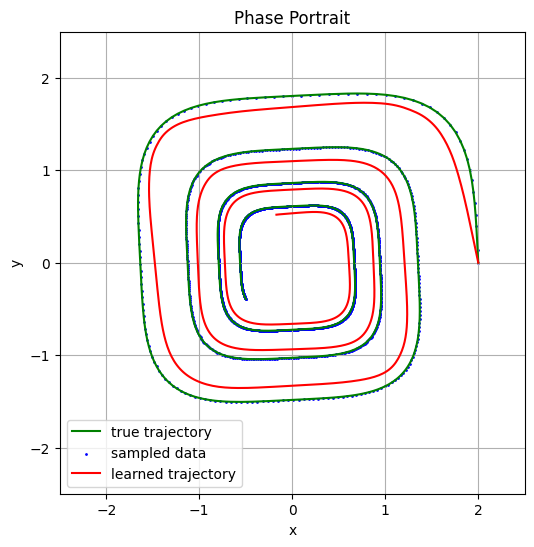

process time: 22.78781270980835 sec
process time: 22.832356691360474 sec
process time: 22.869626760482788 sec
process time: 22.91214656829834 sec
process time: 22.957757472991943 sec
process time: 22.99740481376648 sec
process time: 23.02461552619934 sec
process time: 23.06955599784851 sec
process time: 23.10422706604004 sec
process time: 23.140044927597046 sec
process time: 23.185697317123413 sec
process time: 23.223002672195435 sec
process time: 23.248931646347046 sec
process time: 23.290624141693115 sec
process time: 23.322908401489258 sec
process time: 23.34820055961609 sec
process time: 23.37305498123169 sec
process time: 23.413095712661743 sec
process time: 23.442442417144775 sec
process time: 23.471031427383423 sec
process time: 23.497132301330566 sec
process time: 23.541630506515503 sec
process time: 23.568803071975708 sec
process time: 23.593909978866577 sec
process time: 23.61823606491089 sec
process time: 23.661117792129517 sec
process time: 23.68687081336975 sec
process tim

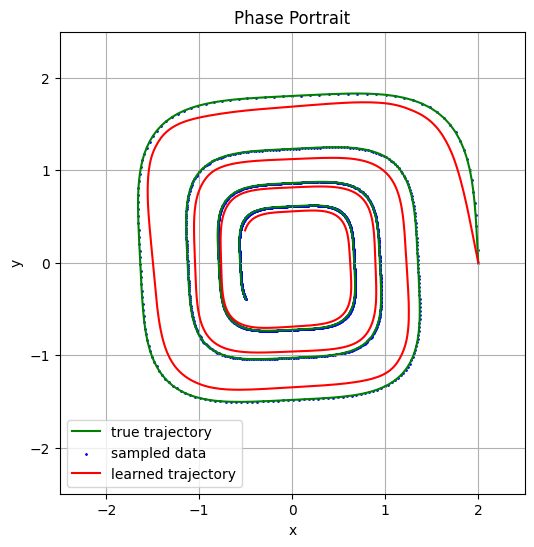

process time: 25.989954948425293 sec


In [15]:
# Train
niters = 400

node = NeuralODE(func=ODEFunc()).to(device)
optimizer = optim.RMSprop(node.parameters(), lr=1e-3)

start_time = time.time()

for iter in tqdm(range(niters + 1)):
  optimizer.zero_grad()
  batch_y0, batch_t, batch_y = get_batch()
  pred_y = node(y0=batch_y0, t=batch_t, solver=rk4)
  loss = torch.mean(torch.abs(pred_y - batch_y))
  loss.backward()
  optimizer.step()

  if iter % 50 == 0:
    with torch.no_grad():
      pred_y = node(y0=true_y0, t=t, solver=rk4)
      loss = torch.mean(torch.abs(pred_y - true_y))
      print('Iter {:04d} | Total Loss {:.6f}'.format(iter, loss.item()))
      visualize(true_y, pred_y)


  end_time = time.time() - start_time
  print('process time: {} sec'.format(end_time))

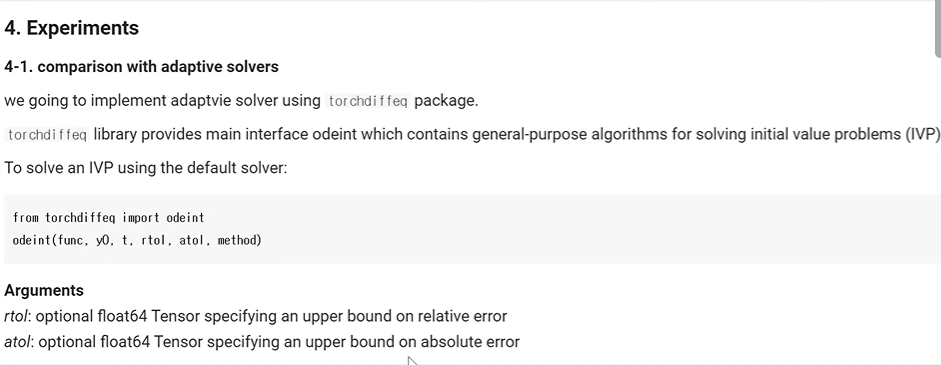

In [16]:
!pip install torchdiffeq

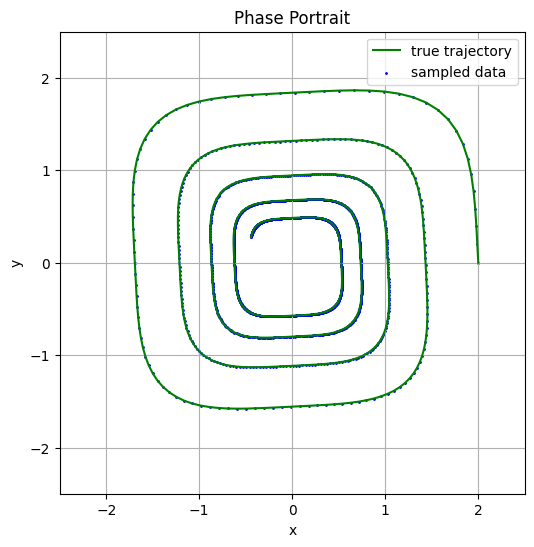

In [17]:
from torchdiffeq import odeint

# Solve the ODE using torchdiffeq's odeint with the rk4 method
true_y_odeint = odeint(Lambda(), true_y0, t, method='rk4')

# Visualize the result from torchdiffeq
visualize(true_y_odeint)

In [19]:
# Train
niters = 400

func = ODEFunc().to(device)
optimizer = optim.RMSprop(func.parameters(), lr=1e-3)

start_time = time.time()

for iter in tqdm(range(niters)):
    optimizer.zero_grad()
    batch_y0, batch_t, batch_y = get_batch()
    y_pred = odeint(func=func, y0=batch_y0, t=batch_t, rtol=1e-7, atol=1e-9, method='dopri5')
    loss = torch.mean(torch.abs(y_pred - batch_y))
    loss.backward()
    optimizer.step()

    if iter % 50 == 0:
      with torch.no_grad():
        func.eval()
        batch_y0, batch_t, batch_y = get_batch()
        y_pred = odeint(func=func, y0=batch_y0, t=batch_t, rtol=1e-7, atol=1e-9, method='dopri5')
        loss = torch.mean(torch.abs(y_pred - batch_y))


end_time = time.time()

  0%|          | 0/400 [00:00<?, ?it/s]

  0%|          | 0/401 [00:00<?, ?it/s]

Iter 0000 | Total Loss 0.944146


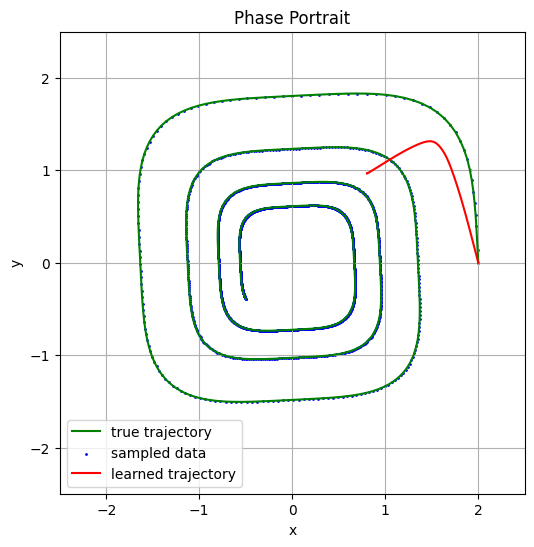

Iter 0050 | Total Loss 0.642181


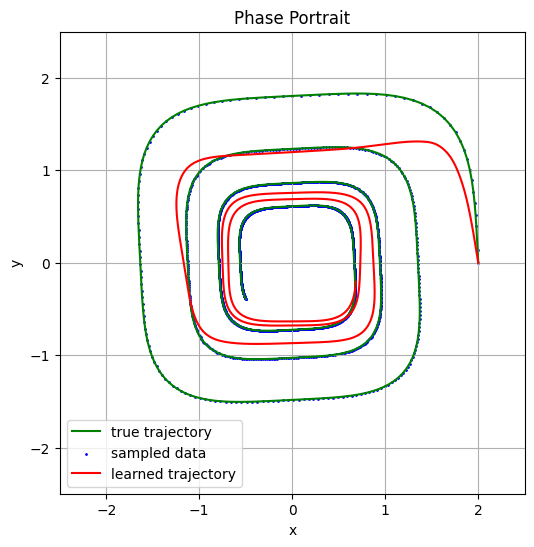

Iter 0100 | Total Loss 0.433294


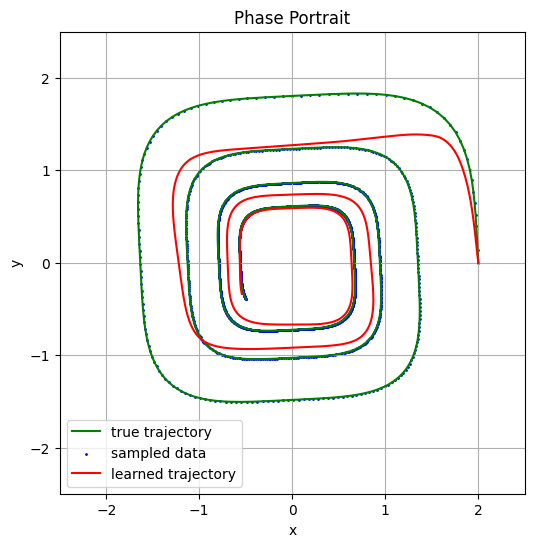

Iter 0150 | Total Loss 0.588638


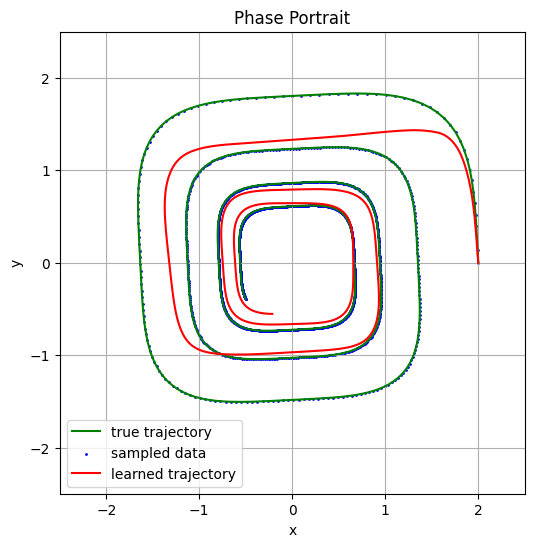

Iter 0200 | Total Loss 0.545306


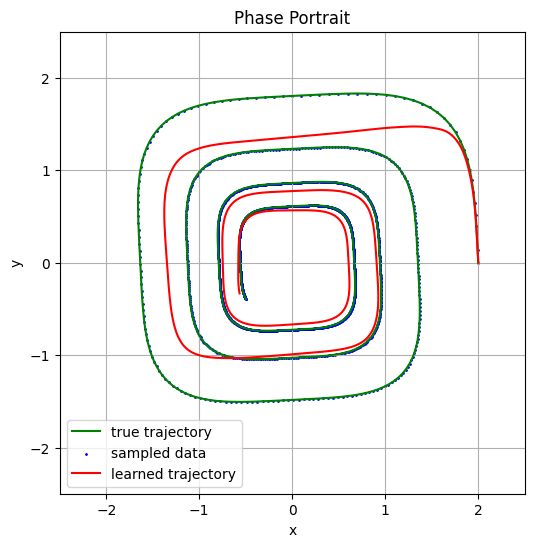

Iter 0250 | Total Loss 0.872108


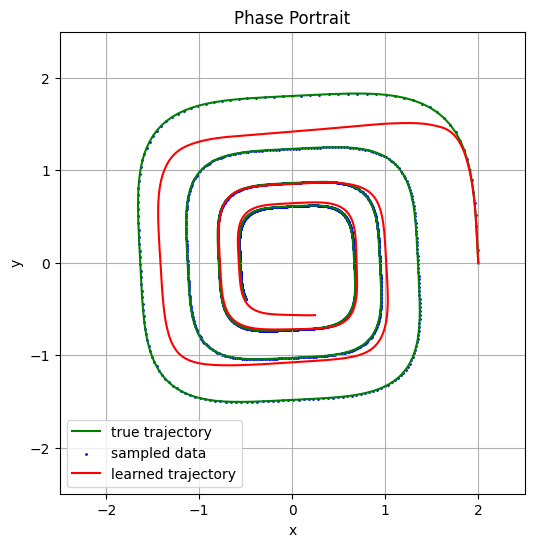

Iter 0300 | Total Loss 0.778282


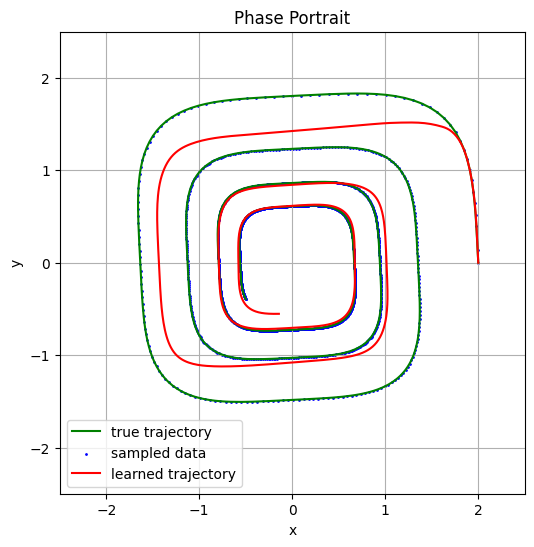

Iter 0350 | Total Loss 1.059057


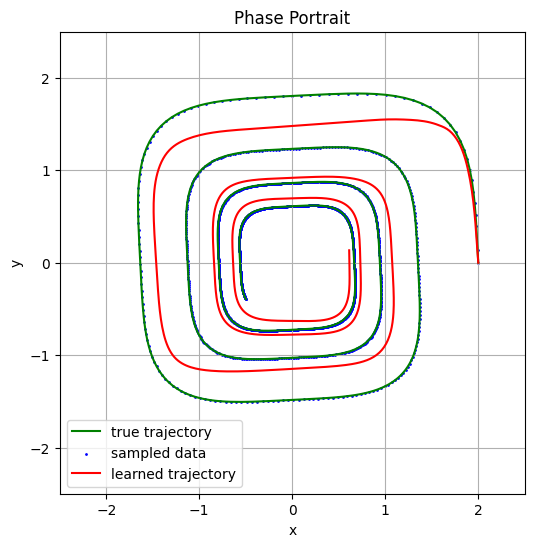

Iter 0400 | Total Loss 1.081492


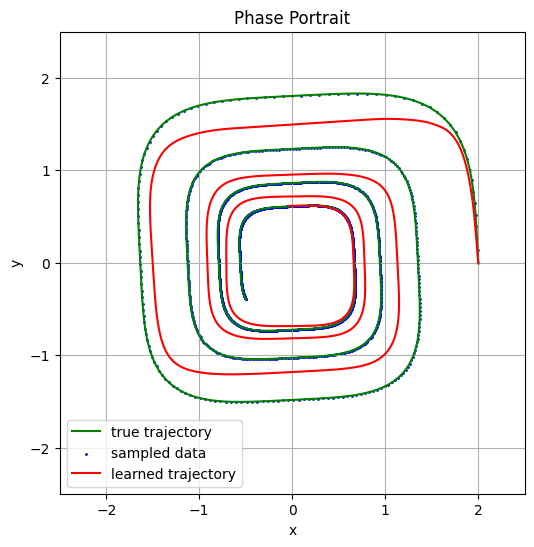

Total Time: 34.65s


In [20]:
## Train
niters = 400

func = ODEFunc().cuda()
optimizer = optim.RMSprop(func.parameters(), lr=1e-3)

start_time = time.time()

for iter in tqdm(range(niters + 1)):
    optimizer.zero_grad()
    batch_y0, batch_t, batch_y = get_batch()
    pred_y = odeint(func=func, y0=batch_y0, t=batch_t, rtol=1e-7, atol=1e-9, method='dopri5')
    loss = torch.mean(torch.abs(pred_y - batch_y))
    loss.backward()
    optimizer.step()

    if iter % 50 == 0:
        with torch.no_grad():
            pred_y = odeint(func, true_y0, t, rtol=1e-7, atol=1e-9, method='dopri5')
            loss = torch.mean(torch.abs(pred_y - true_y))
            print('Iter {:04d} | Total Loss {:.6f}'.format(iter, loss.item()))
            visualize(true_y, pred_y)

end_time = time.time() - start_time
print('Total Time: {:.2f}s'.format(end_time))

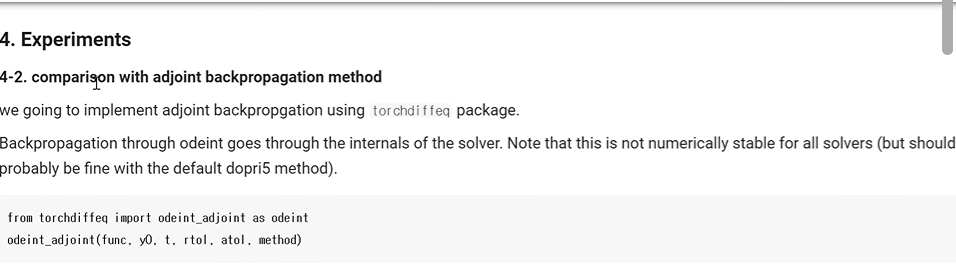

  0%|          | 0/401 [00:00<?, ?it/s]

Iter 0000 | Total Loss 0.902425


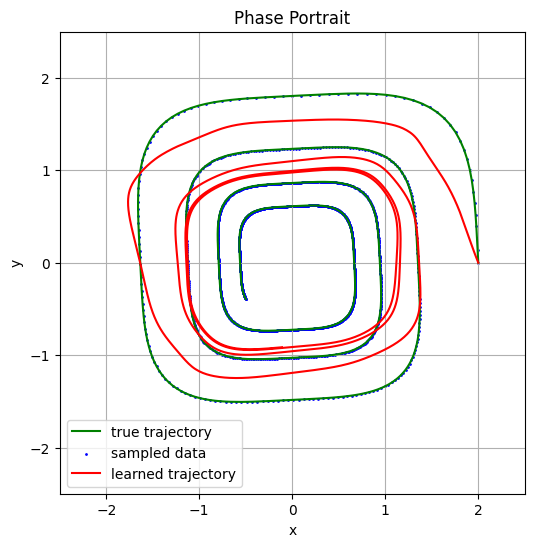

Iter 0050 | Total Loss 0.747797


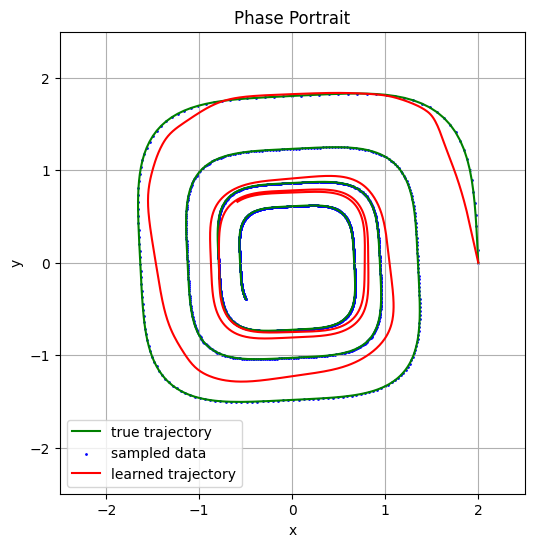

Iter 0100 | Total Loss 0.632452


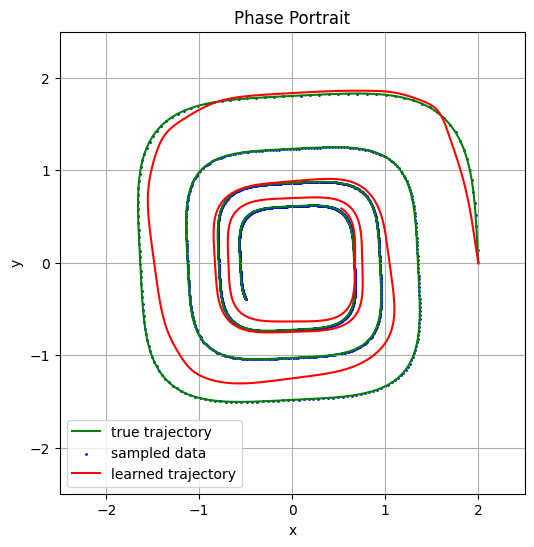

Iter 0150 | Total Loss 0.830939


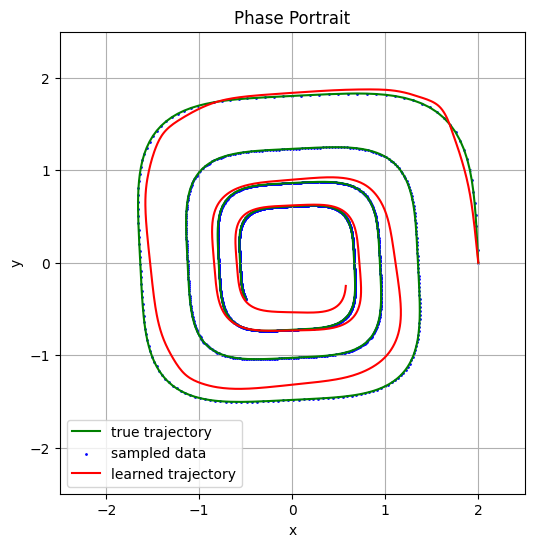

Iter 0200 | Total Loss 0.997420


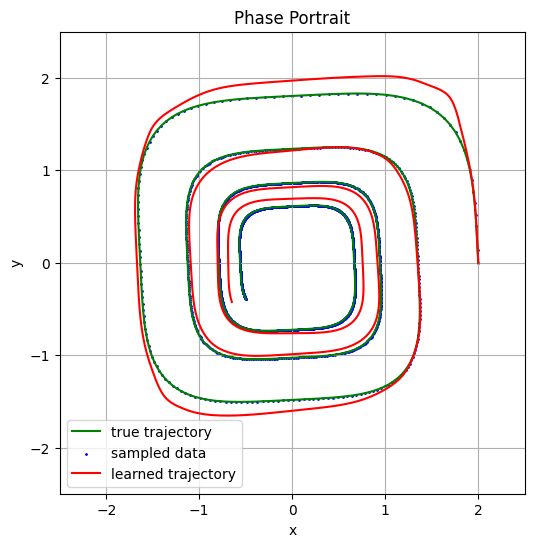

Iter 0250 | Total Loss 0.917371


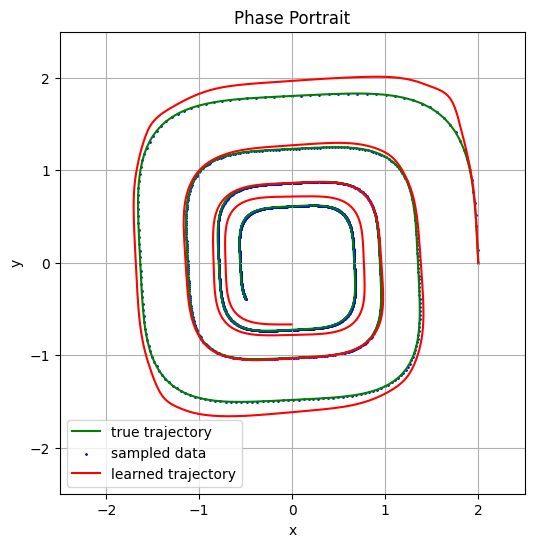

Iter 0300 | Total Loss 0.847920


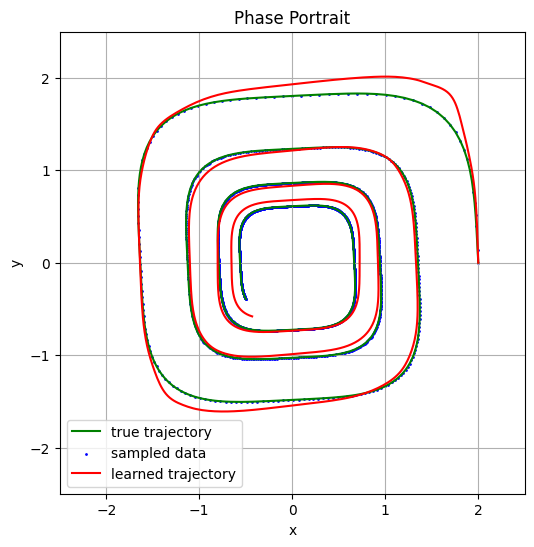

Iter 0350 | Total Loss 1.125236


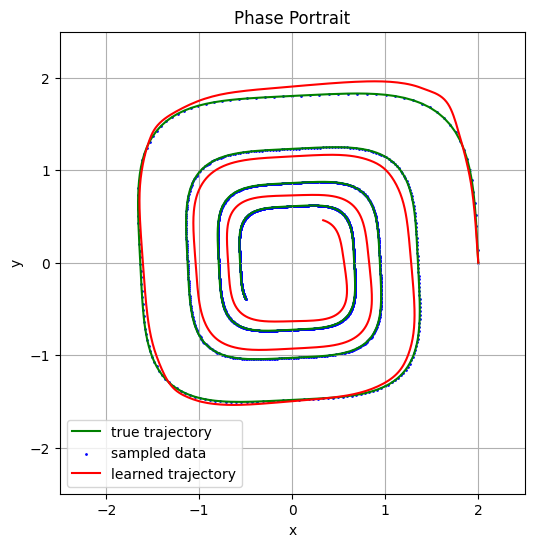

Iter 0400 | Total Loss 0.713515


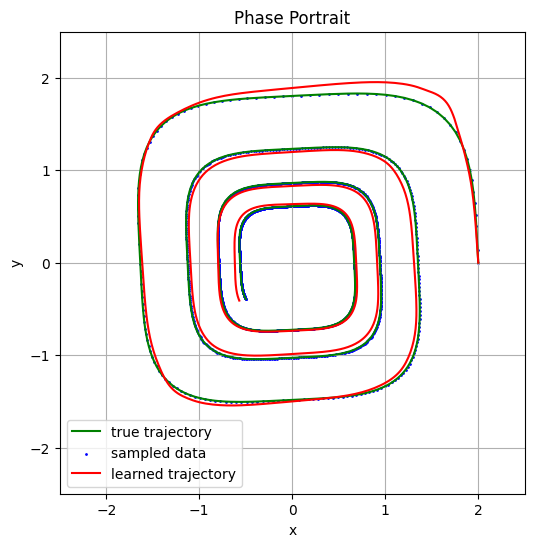

process time: 116.53417801856995 sec


In [22]:
from torchdiffeq import odeint_adjoint

## Train
niters = 400

func = ODEFunc().cuda()
optimizer = optim.RMSprop(func.parameters(), lr=1e-3)

start_time = time.time()

for iter in tqdm(range(niters + 1)):
    optimizer.zero_grad()
    batch_y0, batch_t, batch_y = get_batch()
    pred_y = odeint_adjoint(func=func, y0=batch_y0, t=batch_t, rtol=1e-7, atol=1e-9, method='dopri5')
    loss = torch.mean(torch.abs(pred_y - batch_y))
    loss.backward()
    optimizer.step()

    if iter % 50 == 0:
        with torch.no_grad():
            pred_y = odeint_adjoint(func, true_y0, t, rtol=1e-7, atol=1e-9, method='dopri5')
            loss = torch.mean(torch.abs(pred_y - true_y))
            print('Iter {:04d} | Total Loss {:.6f}'.format(iter, loss.item()))
            visualize(true_y, pred_y)

end_time = time.time() - start_time
print('process time: {} sec'.format(end_time))
